# Take-Home Exercise 3: Data Transformation & Regression
## Assignment Details
**Module Title:** Data Analytics  
**CRN:** 23631  
**Student:** Rory Patrick Sheridan - A00082654  
**Submission File:** `A00082654_Rory.pdf`  
**Dataset:**
Dataset A, a customer-level dataset for a service organisation that is deliberately not analysis-ready, recording age, income, monthly spend, visits, satisfaction, region, membership tier and whether the customer purchased a new service, `DatasetA_Customer.csv`.  
Dataset B, 36 monthly observations from January 2024 to December 2026 of electricity demand, average temperature, a synthetic industrial activity index, a time index and season, `DatasetB_Electricity.csv`.  
**Task:**
Identify and justify data-preparation choices, transform and represent variables appropriately, and apply feature engineering, principal component analysis and regression analysis.

Github Repository:  
https://github.com/Ri-Dearg/da-labs  
Github Notebook:  
https://github.com/Ri-Dearg/da-labs/blob/main/lab3_transform_regression.ipynb


### Libraries
Libraries used.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


### Dataset A: Customer Data


#### Data Overview

In [2]:
# Import Dataset A
df_a = pd.read_csv('customers.csv')
df_a

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
0,C001,45.0,38182.0,758.81,9,7.9,Cork,Standard,Yes
1,C002,45.0,42762.0,553.10,3,4.4,Limerick,Basic,No
2,C003,46.0,33420.0,803.92,13,6.7,Dublin,Premium,Yes
3,C004,32.0,24445.0,404.97,4,5.9,Limerick,Basic,No
4,C005,50.0,78004.0,709.69,3,6.5,Limerick,Standard,Yes
...,...,...,...,...,...,...,...,...,...
67,C068,63.0,51342.0,1037.00,9,8.9,Dublin,Premium,No
68,C069,51.0,67564.0,709.64,3,6.2,Dublin,Basic,Yes
69,C070,31.0,51783.0,973.71,7,6.8,Dublin,Premium,Yes
70,C017,45.0,48205.0,507.44,3,7.9,Cork,Basic,No


In [3]:
# View data stats
df_a.describe()

,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score
count,70.000000,70.000000,72.000000,72.000000,71.000000
mean,38.728571,54695.457143,766.362778,6.513889,6.857746
std,12.566255,26904.020010,218.261558,2.906976,1.569592
min,19.000000,22000.000000,270.500000,2.000000,3.600000
25%,30.000000,36722.000000,588.937500,4.000000,5.800000
50%,39.000000,48205.000000,759.305000,6.000000,6.800000
75%,46.000000,72010.000000,910.507500,8.250000,7.900000
max,72.000000,146183.000000,1397.340000,14.000000,10.000000


In [4]:
# View categorical stats
df_a.describe(exclude='number')

,Customer_ID,Region,Membership,Purchased
count,72,71,71,72
unique,70,4,3,2
top,C017,Dublin,Basic,No
freq,2,30,34,40


#### Types

In [5]:
# Explore structure of the data
df_a.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         72 non-null     str    
 1   Age                 70 non-null     float64
 2   Annual_Income_EUR   70 non-null     float64
 3   Monthly_Spend_EUR   72 non-null     float64
 4   Visits_Per_Month    72 non-null     int64  
 5   Satisfaction_Score  71 non-null     float64
 6   Region              71 non-null     str    
 7   Membership          71 non-null     str    
 8   Purchased           72 non-null     str    
dtypes: float64(4), int64(1), str(4)
memory usage: 5.2 KB


#### Distributions

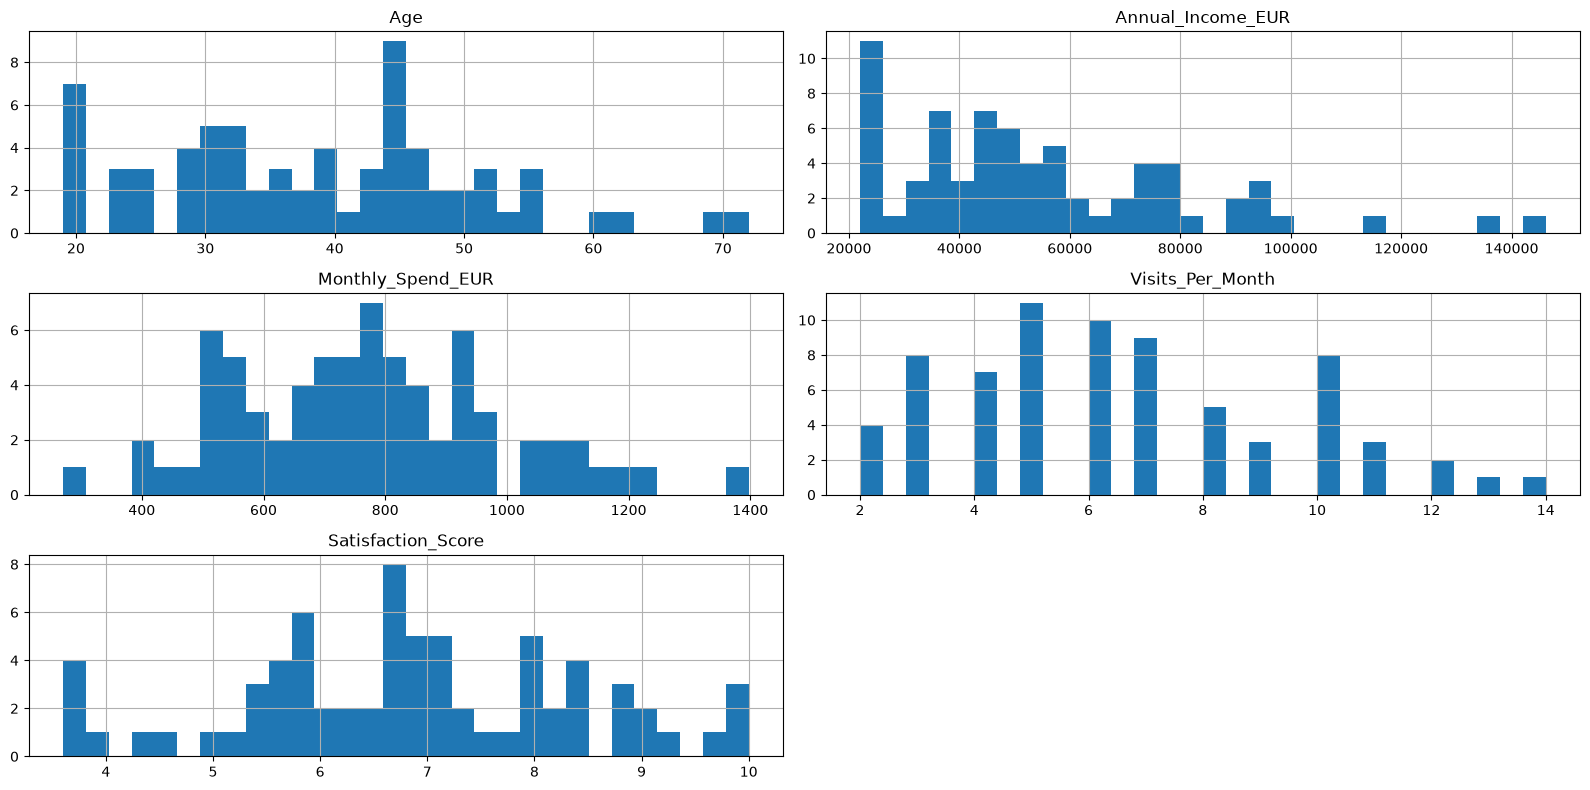

In [6]:
# Histograms for the distribution of each numeric variable
df_a.hist(figsize=(16, 8), bins=30)
plt.tight_layout()

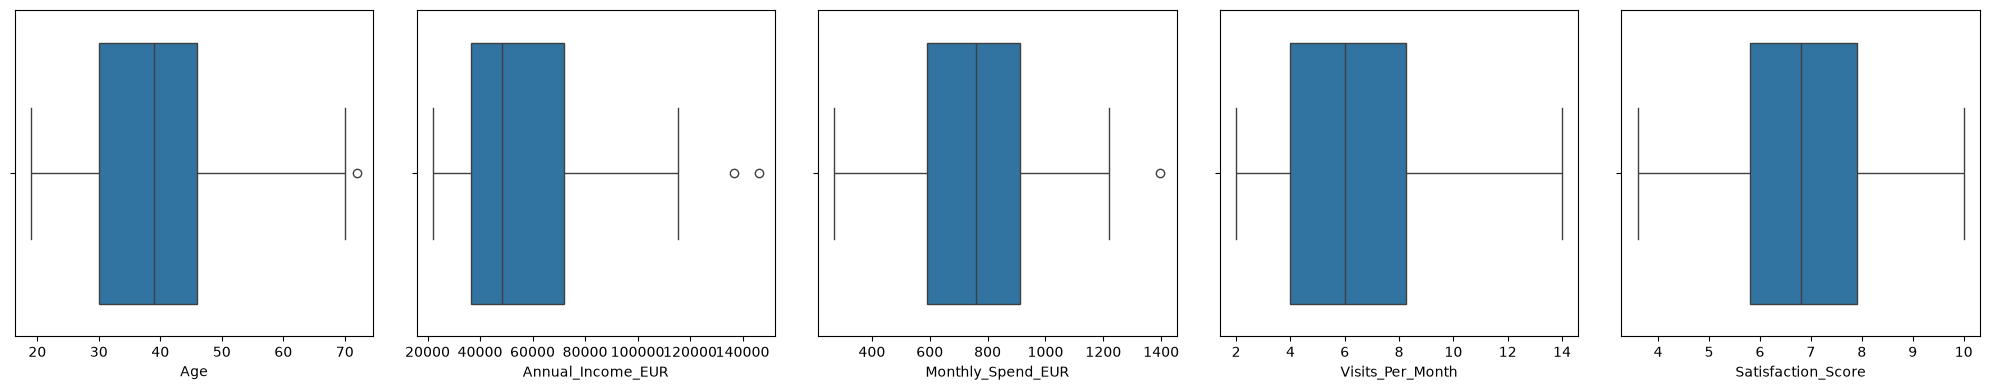

In [7]:
# Boxplots to check each numeric variable for outliers
cols = df_a.drop(columns='Customer_ID').select_dtypes('number')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes.flat, cols, strict=True):
    sns.boxplot(x=df_a[col], ax=ax)
plt.tight_layout()

In [8]:
# Skewness of each numeric variable
df_a.skew(numeric_only=True).round(2)

Age                   0.34
Annual_Income_EUR     1.19
Monthly_Spend_EUR     0.37
Visits_Per_Month      0.49
Satisfaction_Score   -0.07
dtype: float64

In [9]:
# Rows with a value beyond the 1.5 x IQR fences
num_a = df_a.select_dtypes('number')
q1_a, q3_a = num_a.quantile(0.25), num_a.quantile(0.75)
iqr_a = q3_a - q1_a
outside = (num_a < q1_a - 1.5 * iqr_a) | (num_a > q3_a + 1.5 * iqr_a)
df_a.loc[outside.any(axis=1), ['Customer_ID', *num_a.columns]]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score
8,C009,45.0,146183.0,1397.34,5,6.9
40,C041,72.0,37223.0,633.65,3,6.9
56,C057,36.0,136914.0,1103.29,5,6.4


#### Categorical Counts

In [10]:
# Counts of each categorical variable, including missing values
for col in ['Region', 'Membership', 'Purchased']:
    print(df_a[col].value_counts(dropna=False), '\n')

Region
Dublin      30
Limerick    16
Cork        14
Galway      11
NaN          1
Name: count, dtype: int64 

Membership
Basic       34
Standard    23
Premium     14
NaN          1
Name: count, dtype: int64 

Purchased
No     40
Yes    32
Name: count, dtype: int64 



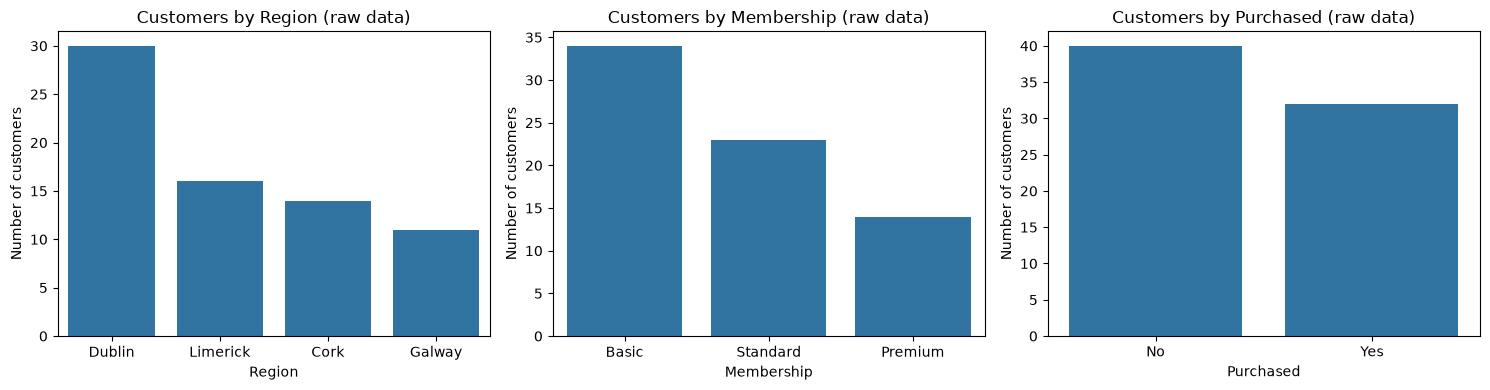

In [11]:
# Countplots of the categorical variables
orders = {
    'Region': df_a['Region'].value_counts().index,
    'Membership': ['Basic', 'Standard', 'Premium'],
    'Purchased': ['No', 'Yes'],
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, order) in zip(axes, orders.items(), strict=True):
    sns.countplot(data=df_a, x=col, order=order, ax=ax)
    ax.set(ylabel='Number of customers', title=f'Customers by {col} (raw data)')
plt.tight_layout()

## Question 1: Audit, Impute, and Transform Dataset A

### a) Audit the dataset before analysis. Report the number of rows, exact duplicate rows, and missing values by variable. Remove only exact duplicate records and report the resulting sample size.

**Rows:** The raw dataset has 72 rows and 9 columns.

**Exact duplicate rows:** 2. They are second copies of customers `C017` and `C044` with every value identical to the original rows.

**Missing values by variable:**

| Variable | Missing values | Customers |
|:--|--:|:--|
| `Customer_ID` | 0 | |
| `Age` | 2 | C007, C060 |
| `Annual_Income_EUR` | 2 | C019, C060 |
| `Monthly_Spend_EUR` | 0 | |
| `Visits_Per_Month` | 0 | |
| `Satisfaction_Score` | 1 | C030 |
| `Region` | 1 | C038 |
| `Membership` | 1 | C049 |
| `Purchased` | 0 | |
| **Total** | **7** | **6 customers** |

The duplicate rows have no missing values, so these counts are the same before and after they are removed. Customer C060 is missing both `Age` and `Annual_Income_EUR`.

I removed the two duplicates. After removal every `Customer_ID` is unique. No other rows were removed.

**Resulting sample size:** n = 70 customers (72 - 2).

**Expected consequence:** C017 and C044 no longer count twice, so they don't get double weight in any summary or test. All later analysis of Dataset A uses the 70 unique customers.

In [12]:
df_a.shape

(72, 9)

In [13]:
# Check for duplicates
df_a.duplicated().sum()

np.int64(2)

In [14]:
# Show duplicates
df_a[df_a.duplicated(keep=False)]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
16,C017,45.0,48205.0,507.44,3,7.9,Cork,Basic,No
43,C044,35.0,22000.0,509.84,10,5.8,Dublin,Standard,Yes
70,C017,45.0,48205.0,507.44,3,7.9,Cork,Basic,No
71,C044,35.0,22000.0,509.84,10,5.8,Dublin,Standard,Yes


In [15]:
# Check for missing values by variable
df_a.isna().sum()

Customer_ID           0
Age                   2
Annual_Income_EUR     2
Monthly_Spend_EUR     0
Visits_Per_Month      0
Satisfaction_Score    1
Region                1
Membership            1
Purchased             0
dtype: int64

In [16]:
# Show the rows with missing values
df_a[df_a.isna().any(axis=1)]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
6,C007,NaN,23907.0,440.15,5,4.9,Dublin,Basic,No
18,C019,32.0,NaN,647.99,4,8.5,Dublin,Basic,Yes
29,C030,29.0,33932.0,522.00,8,NaN,Limerick,Basic,No
37,C038,23.0,33164.0,591.17,6,7.3,NaN,Standard,No
48,C049,53.0,25969.0,398.47,4,3.6,Galway,NaN,No
59,C060,NaN,NaN,693.82,2,5.4,Dublin,Basic,No


In [17]:
# Remove exact duplicates only, keeping the first copy
df_dedup = df_a.drop_duplicates()
df_dedup.shape

(70, 9)

### b) For every variable with missing values, choose an imputation strategy and justify it. Your answer should explicitly consider mean, median and mode where relevant. For Annual_Income_EUR, compare the mean and median before deciding.

The statistics are calculated from the observed values of the 70 de-duplicated customers.

| Variable | Missing | Mean | Median | Mode | Skewness | Strategy | Imputed value |
|:--|--:|--:|--:|:--|--:|:--|:--|
| `Age` | 2 | 38.69 | 39 | 19 and 45 (tied) | 0.35 | Median | 39 |
| `Annual_Income_EUR` | 2 | 55,271.72 | 48,496 | 22,000 | 1.17 | Median | 48,496 |
| `Satisfaction_Score` | 1 | 6.86 | 6.80 | 6.8 and 7.2 (tied) | -0.07 | Mean | 6.86 |
| `Region` | 1 | n/a | n/a | Dublin (29 of 69) | n/a | Mode | Dublin |
| `Membership` | 1 | n/a | Standard | Basic (33 of 69) | n/a | Mode | Basic |

- **`Annual_Income_EUR`:** The mean (€55,272) is €6,776 (~14%) higher than the median (€48,496). Income is right-skewed (skewness 1.17), with some high earners impacting distribution. The median is more robust to outliers, so it represents a typical customer better. The mode is €22,000, and is the lowest income in the data. It would place customers in the lower range and would not be representative either. For these reasons, I have chosen the median.
- **`Age`:** The mean and median are almost the same (38.7 and 39), so both are valid choices. I chose the median because age is recorded in whole years and there is a mild right tail of older customers. The mode is not useful, as there are two (19 and 45). 19 is the youngest age so the mode does not represent the customer base.
- **`Satisfaction_Score`:** The distribution is close to symmetric with no extreme values. Therefore the mean (6.86) is a valid choice for this feature. It is almost identical to the median (6.80). Again there are two modes (6.8, 7.2), both relatively close to the mean and median. In this case, I have chosen the mean.
- **`Region`:** Region is nominal, so it has no mean or median. Dublin is the only mode, so that has been chosen for imputation. An unknown constant would create an artificial category, and since only one row is affected, it is unnecessary.
- **`Membership`:** Membership is ordinal, so it has both a median and a mode. Standard is the median, but it is only just ahead of Basic. Basic is 47.8% of the values. The mode is Basic, the most common tier, so I have chosen the mode.

**Expected consequence:** All 70 customers are kept, where dropping incomplete rows would lose 6 (8.6%). The imputed values sit at the centre of each variable, so spread and correlations are very slightly understated, and Dublin and Basic each gain one customer. With only one or two values per variable, the effect is small.

In [18]:
# Mean, median, mode and skewness of the numerical variables with missing values
num_missing = ['Age', 'Annual_Income_EUR', 'Satisfaction_Score']
impute_stats = df_dedup[num_missing].agg(['count', 'mean', 'median', 'skew']).T
impute_stats['mode'] = [df_dedup[col].mode().tolist() for col in num_missing]
impute_stats.round(2)

,count,mean,median,skew,mode
Age,68.0,38.69,39.0,0.35,"[19.0, 45.0]"
Annual_Income_EUR,68.0,55271.72,48496.0,1.17,[22000.0]
Satisfaction_Score,69.0,6.86,6.8,-0.07,"[6.8, 7.2]"


In [19]:
# Compare the mean and median of income
income_mean = df_dedup['Annual_Income_EUR'].mean()
income_median = df_dedup['Annual_Income_EUR'].median()
print(f'Mean = {income_mean:,.2f}, median = {income_median:,.0f}')
print(
    f'Difference = {income_mean - income_median:,.0f} '
    f'({income_mean / income_median - 1:.1%} above the median)'
)
print(f"Maximum = {df_dedup['Annual_Income_EUR'].max():,.0f}")

Mean = 55,271.72, median = 48,496
Difference = 6,776 (14.0% above the median)
Maximum = 146,183


In [20]:
# Frequencies of the categorical variables with missing values
print(df_dedup['Region'].value_counts(), '\n')
print(df_dedup['Membership'].value_counts())

Region
Dublin      29
Limerick    16
Cork        13
Galway      11
Name: count, dtype: int64 

Membership
Basic       33
Standard    22
Premium     14
Name: count, dtype: int64


In [21]:
# Median category of Membership, using the tier order (2 = Standard)
df_dedup['Membership'].map({'Basic': 1, 'Standard': 2, 'Premium': 3}).median()

np.float64(2.0)

In [22]:
# Impute each variable with the chosen statistic
df_clean = df_dedup.copy()
df_clean['Age'] = df_clean['Age'].fillna(df_dedup['Age'].median())
df_clean['Annual_Income_EUR'] = df_clean['Annual_Income_EUR'].fillna(
    df_dedup['Annual_Income_EUR'].median()
)
df_clean['Satisfaction_Score'] = df_clean['Satisfaction_Score'].fillna(
    df_dedup['Satisfaction_Score'].mean()
)
df_clean['Region'] = df_clean['Region'].fillna(df_dedup['Region'].mode()[0])
df_clean['Membership'] = df_clean['Membership'].fillna(df_dedup['Membership'].mode()[0])
df_clean.isna().sum().sum()

np.int64(0)

In [23]:
# Show the imputed rows
df_clean[df_dedup.isna().any(axis=1)]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
6,C007,39.0,23907.0,440.15,5,4.900000,Dublin,Basic,No
18,C019,32.0,48496.0,647.99,4,8.500000,Dublin,Basic,Yes
29,C030,29.0,33932.0,522.00,8,6.857971,Limerick,Basic,No
37,C038,23.0,33164.0,591.17,6,7.300000,Dublin,Standard,No
48,C049,53.0,25969.0,398.47,4,3.600000,Galway,Basic,No
59,C060,39.0,48496.0,693.82,2,5.400000,Dublin,Basic,No


### c) Encode Region and Membership appropriately for analysis. Explain why arbitrary labels such as Dublin=1, Cork=2, Galway=3, Limerick=4 would create a false ordering for Region, and discuss whether the ordering of Membership justifies an ordinal representation.

**Region: one-hot (dummy) encoding**
Region is nominal, as the four cities are names with no natural order, so each region gets its own 0/1 column. `drop_first=True` drops the first category alphabetically, Cork, which becomes the reference category: a Cork customer has 0 in `Region_Dublin`, `Region_Galway` and `Region_Limerick`. One column must be dropped because the four columns add up to 1, so keeping them with an intercept would create perfect multicollinearity.

Labels such as Dublin=1, Cork=2, Galway=3, Limerick=4 would create false ordering, with methods that read the column finding quantities or importances, which they are not.
- Numbers imply an order, but regions have no order or meaning.
- It implies equal unit distances which does not apply, for example Limerick would be 3 units from Dublin. Distance-based methods, such as PCA or clustering, would create groupings based on these numbers despite them being unrelated, creating false correlations.
- Regression would fit one slope for Region, forcing the change from Dublin to Cork to equal the change from Galway to Limerick. Numbering the regions in a different order would give different results.

**Membership: ordinal encoding**
Membership has a genuine order, Basic < Standard < Premium, meaning ordinal encoding is utilised. `Membership_Ord` = 1, 2, 3 keeps the order in a single column.

Ordinal representation makes sense with one caveat: integer codes assume equal steps, so Basic to Standard measures the same as Standard to Premium. This is an assumption, as these values do not have defined units. If a model needed to measure the values with unequal effects, one-hot encoding would be the better option.

**Expected consequence:** Region enters any analysis as three 0/1 columns, each compared with Cork. Membership becomes a single ordered columnwith equal steps between tiers.

In [24]:
# One-hot encode Region; drop_first makes Cork (first alphabetically) the reference category
region_dummies = pd.get_dummies(df_clean['Region'], prefix='Region', dtype=int, drop_first=True)
df_clean_encode = pd.concat([df_clean, region_dummies], axis=1).drop(columns='Region')
df_clean_encode

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Membership,Purchased,Region_Dublin,Region_Galway,Region_Limerick
0,C001,45.0,38182.0,758.81,9,7.9,Standard,Yes,0,0,0
1,C002,45.0,42762.0,553.10,3,4.4,Basic,No,0,0,1
2,C003,46.0,33420.0,803.92,13,6.7,Premium,Yes,1,0,0
3,C004,32.0,24445.0,404.97,4,5.9,Basic,No,0,0,1
4,C005,50.0,78004.0,709.69,3,6.5,Standard,Yes,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
65,C066,33.0,72240.0,1190.11,14,7.5,Premium,No,0,0,1
66,C067,30.0,22000.0,936.59,12,8.3,Premium,No,1,0,0
67,C068,63.0,51342.0,1037.00,9,8.9,Premium,No,1,0,0
68,C069,51.0,67564.0,709.64,3,6.2,Basic,Yes,1,0,0


In [25]:
# Ordinal encode Membership in tier order, replacing the text column
df_clean_encode['Membership_Ord'] = df_clean['Membership'].map(
    {'Basic': 1, 'Standard': 2, 'Premium': 3}
)
df_clean_encode = df_clean_encode.drop(columns='Membership')
df_clean_encode

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Purchased,Region_Dublin,Region_Galway,Region_Limerick,Membership_Ord
0,C001,45.0,38182.0,758.81,9,7.9,Yes,0,0,0,2
1,C002,45.0,42762.0,553.10,3,4.4,No,0,0,1,1
2,C003,46.0,33420.0,803.92,13,6.7,Yes,1,0,0,3
3,C004,32.0,24445.0,404.97,4,5.9,No,0,0,1,1
4,C005,50.0,78004.0,709.69,3,6.5,Yes,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...
65,C066,33.0,72240.0,1190.11,14,7.5,No,0,0,1,3
66,C067,30.0,22000.0,936.59,12,8.3,No,1,0,0,3
67,C068,63.0,51342.0,1037.00,9,8.9,No,1,0,0,3
68,C069,51.0,67564.0,709.64,3,6.2,Yes,1,0,0,1


### d) Standardise Age, Annual_Income_EUR, Monthly_Spend_EUR, Visits_Per_Month and Satisfaction_Score. Verify numerically that the standardised variables have an approximate mean 0 and standard deviation 1.

The five variables have greatly differing numeric values, with differing scales: income has a standard deviation of €26,621, while satisfaction has a standard deviation of 1.57 points. Any method based on distance or variance, such as PCA, would see income as having more impact. Standardising will convert each variable to standard deviation units, therefore making them comparable on the same scale:

z = (x - mean) / SD

Each variable's mean and sample standard deviation (n - 1) after imputation are used. The z-scores are added as new columns with a `_z` suffix, so the original values are kept.

| Standardised variable | Mean | Standard deviation |
|:--|--:|--:|
| `Age_z` | 0.00 | 1.00 |
| `Annual_Income_EUR_z` | 0.00 | 1.00 |
| `Monthly_Spend_EUR_z` | 0.00 | 1.00 |
| `Visits_Per_Month_z` | 0.00 | 1.00 |
| `Satisfaction_Score_z` | 0.00 | 1.00 |

All five means are 0 (apart from floating-point rounding), and all five standard deviations are 1.

**Expected consequence:** The variables have values that can be compared and combined equally, while the shape of each distribution and correlations stay the same.

In [26]:
# Standard deviation of each variable before standardising
num_cols = [
    'Age',
    'Annual_Income_EUR',
    'Monthly_Spend_EUR',
    'Visits_Per_Month',
    'Satisfaction_Score',
]
df_clean[num_cols].std().round(2)

Age                      12.54
Annual_Income_EUR     26621.21
Monthly_Spend_EUR       216.88
Visits_Per_Month          2.89
Satisfaction_Score        1.57
dtype: float64

In [27]:
# Standardise the five numerical variables into new z-score columns
z_scores = (df_clean[num_cols] - df_clean[num_cols].mean()) / df_clean[num_cols].std()
df_clean = pd.concat([df_clean, z_scores.add_suffix('_z')], axis=1)
z_cols = [f'{col}_z' for col in num_cols]
df_clean[z_cols].head()

,Age_z,Annual_Income_EUR_z,Monthly_Spend_EUR_z,Visits_Per_Month_z,Satisfaction_Score_z
0,0.502570,-0.634687,-0.068775,0.860713,0.663381
1,0.502570,-0.462644,-1.017255,-1.216870,-1.564805
2,0.582343,-0.813567,0.139216,2.245769,-0.100568
3,-0.534479,-1.150704,-1.700247,-0.870606,-0.609868
4,0.901435,0.861188,-0.295256,-1.216870,-0.227893


In [28]:
# Verify the standardised variables have mean 0 and standard deviation 1
df_clean[z_cols].agg(['mean', 'std']).T

,mean,std
Age_z,-2.553513e-16,1.0
Annual_Income_EUR_z,6.185528e-17,1.0
Monthly_Spend_EUR_z,4.662937e-16,1.0
Visits_Per_Month_z,3.092764e-17,1.0
Satisfaction_Score_z,5.659164e-16,1.0


### e) Inspect the distribution of Annual_Income_EUR. Apply a log10 transformation and compare the raw and transformed distributions using a suitable graph and a numerical measure such as skewness. Explain why scaling and log transformation solve different problems.

`Annual_Income_EUR` is right-skewed, with a long upper tail of high earners up to €146,183. €22,000 is also a peak, which looks like a floor in how income was recorded. These values are kept, as there is no evidence they are wrong.

A log10 transformation ws applied and added as a new column, `Log10_Income`. On this scale each extra unit is a tenfold increase in income.

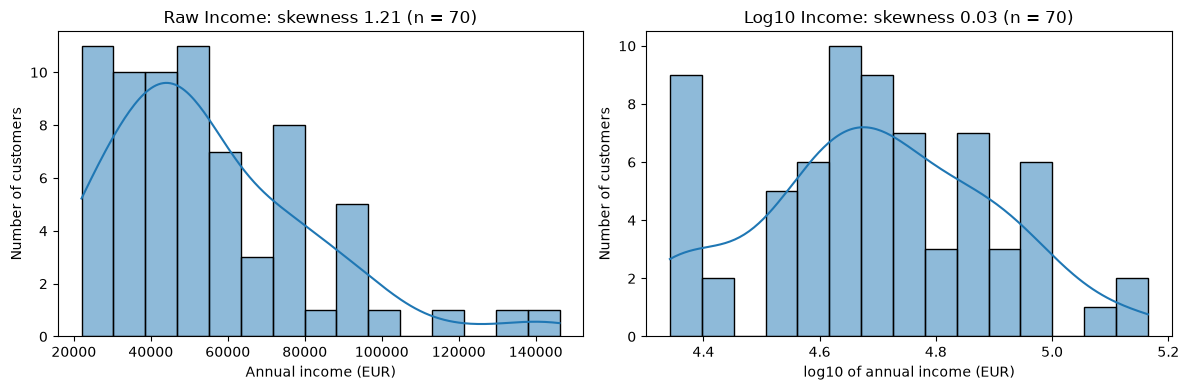

Comparison for the 70 customers after imputation:

| | Raw income | Log10 income |
|:--|--:|--:|
| Skewness | 1.21 | 0.03 |
| Mean | 55,078 | 4.694 |
| Median | 48,496 | 4.686 |

The log transformation decreases the effect of the upper tail, so the distribution shifts closer to normal. Skewness falls from 1.21 to 0.03, with the difference between mean and median shrinking. The spike at €22,000 remains becuase transformations do not separate identical values.

**Why scaling and log transformation solve different problems:**
- **Scaling** is a linear change. It sets the mean to 0 and the standard deviation to 1. This way variables in different units can be compared but it does not change the distribution shape or skew. For example, standardised income still has a skewness of 1.21.
- **Log transformation** is non-linear. It compresses large values more than small ones, reducing skew and the effect of extreme values oin distribution. However, it does not create a comparable scale across variables.
- Scaling deals with differences in units, and log deals with skewness. They can be combined by taking the log first and then standardising.

**Expected consequence:** Analyses using `Log10_Income` are less driven by the highest earners, with effects read per tenfold change in income rather than in euro.

In [29]:
# Add log10 of income as a new column
df_clean['Log10_Income'] = np.log10(df_clean['Annual_Income_EUR'])

In [30]:
# Compare raw and log10 income: skewness, mean and median
income = df_clean[['Annual_Income_EUR', 'Log10_Income']]
income.agg(['skew', 'mean', 'median']).T.round(3)

,skew,mean,median
Annual_Income_EUR,1.209,55078.129,48496.000
Log10_Income,0.028,4.694,4.686


In [31]:
# Standardising does not change the shape: skewness of raw and standardised income
print(f"Raw: {df_clean['Annual_Income_EUR'].skew():.2f}")
print(f"Standardised: {df_clean['Annual_Income_EUR_z'].skew():.2f}")

Raw: 1.21
Standardised: 1.21


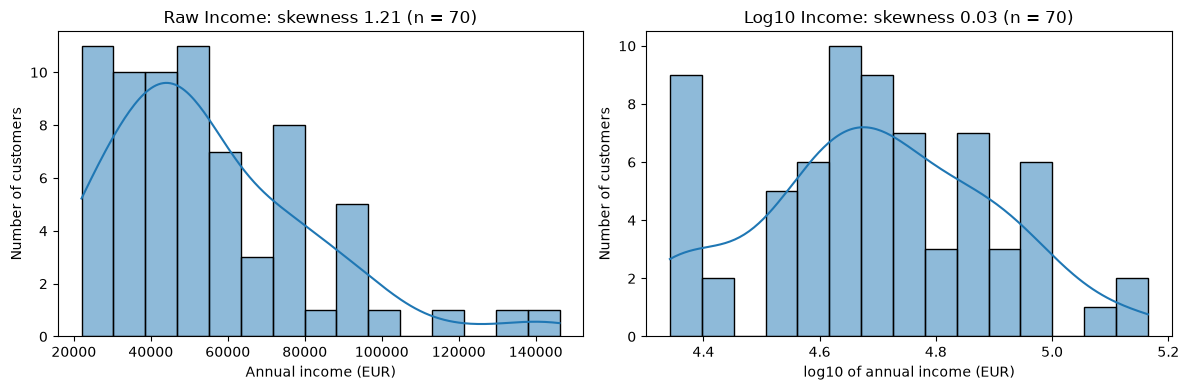

In [32]:
# Histograms of raw and log10 income
skew_raw = df_clean['Annual_Income_EUR'].skew()
skew_log = df_clean['Log10_Income'].skew()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_clean, x='Annual_Income_EUR', bins=15, kde=True, ax=axes[0])
axes[0].set(
    xlabel='Annual income (EUR)',
    ylabel='Number of customers',
    title=f'Raw Income: skewness {skew_raw:.2f} (n = {len(df_clean)})',
)
sns.histplot(data=df_clean, x='Log10_Income', bins=15, kde=True, ax=axes[1])
axes[1].set(
    xlabel='log10 of annual income (EUR)',
    ylabel='Number of customers',
    title=f'Log10 Income: skewness {skew_log:.2f} (n = {len(df_clean)})',
)
plt.tight_layout()